# Velora Brewing - Statistics and Feature Engineering
**Week 6 deliverable: Statistical quality and profitability analysis**

**What is this step for?** The EDA showed patterns; statistics tells us which patterns are **real** and how **big** they are, and feature engineering prepares the inputs for the machine learning in the next step.

**Four ideas to remember**
- **Confidence interval (CI):** a range that very likely holds the true value.
- **p-value:** how surprising the data would be if there were no real effect.
- **Effect size:** how big the effect is. Significant does not mean important.
- **Multiple testing:** run many tests and some look significant by luck, so we correct (Holm).

Code: `src/stats_utils.py`, `src/statistics_analysis.py`, `src/features.py`. Run the cells in order with **Shift+Enter**.

In [1]:
import os, sys
from pathlib import Path

PROJECT = None   # Only if the next lines fail: put your project path here, e.g. r"C:\Users\you\velora-brewing-analytics"
start = Path(PROJECT) if PROJECT else Path.cwd()
for folder in [start, *start.parents]:
    if (folder / "src" / "load_data.py").exists():
        os.chdir(folder); break
else:
    raise FileNotFoundError("Project folder not found. Set PROJECT above to your project folder path.")
sys.path.append("src")
print("Working folder:", Path.cwd())

import calendar
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display
from matplotlib.patches import Rectangle
from load_data import load_data_tables
from cleaning import clean_all
from statistics_analysis import run_all
from features import build_all, TRAIN_END
import stats_utils as su

sns.set_theme(style="whitegrid"); plt.rcParams.update({"axes.titleweight": "bold", "axes.titlesize": 12})
BLUE, ORANGE, GREY, GREEN = "#2E6F95", "#E07A5F", "#9AA5B1", "#3D9970"
pd.set_option("display.width", 220, "display.max_columns", 30, "display.max_colwidth", 80)
FIG = Path("reports/figures"); FIG.mkdir(parents=True, exist_ok=True)
def save(fig, name):
    fig.tight_layout(); fig.savefig(FIG / f"{name}.png", dpi=130, bbox_inches="tight"); plt.show()

clean, *_ = clean_all(load_data_tables())
cis, tests, extra = run_all(clean)
print(f"{len(tests)} hypothesis tests and {len(cis)} confidence intervals computed")

Working folder: /home/claude/velora-brewing-analytics


34 hypothesis tests and 37 confidence intervals computed


## 1. Confidence intervals: how precise are our numbers?
**How to read:** each dot is an estimate and the line is its 95% confidence interval. A short line means a precise estimate; two intervals that do not overlap point to a real difference.

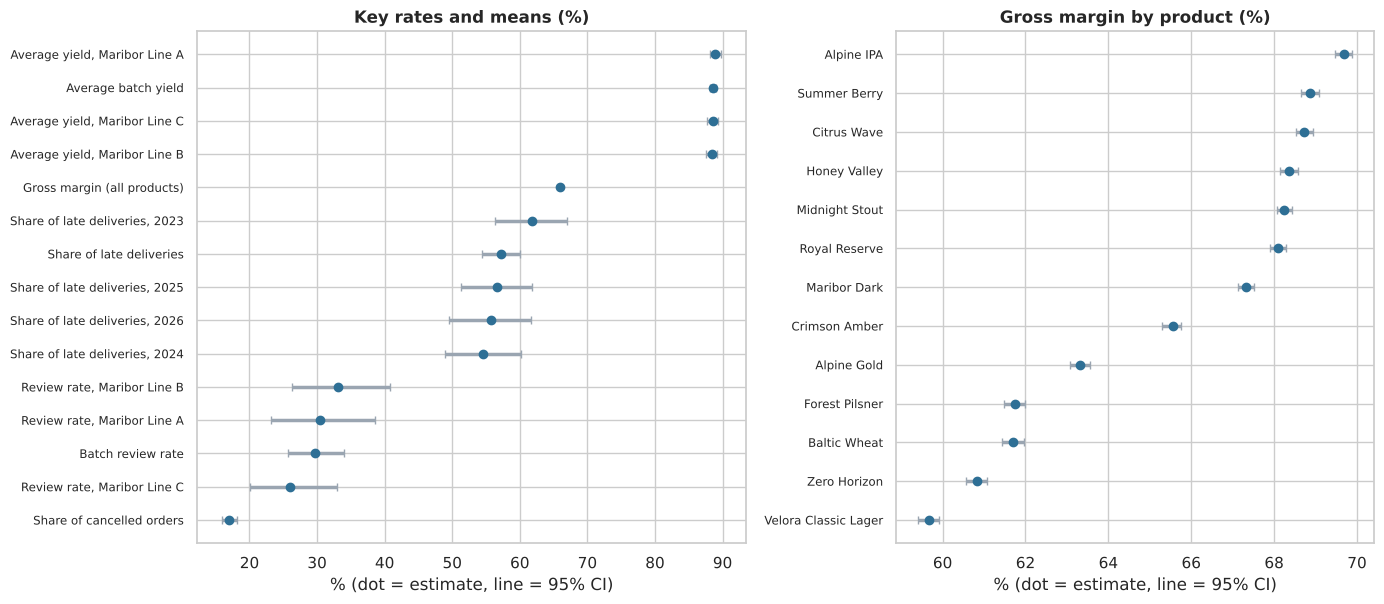

,quantity,estimate,low,high,n
0,Average batch yield,88.6,88.1,89.1,465
1,"Average yield, Maribor Line A",89.0,88.1,89.8,135
2,"Average yield, Maribor Line B",88.4,87.6,89.2,157
3,"Average yield, Maribor Line C",88.5,87.7,89.3,173
5,Batch review rate,29.7,25.7,34.0,465
6,"Review rate, Maribor Line A",30.4,23.2,38.6,135
7,"Review rate, Maribor Line B",33.1,26.2,40.8,157
8,"Review rate, Maribor Line C",26.0,20.0,33.0,173
9,Share of late deliveries,57.2,54.4,60.0,1200
10,"Share of late deliveries, 2023",61.8,56.3,67.1,309


In [2]:
pct = cis[(cis["unit"] == "%") & ~cis["quantity"].str.startswith("Gross margin, ")].sort_values("estimate")
prod = cis[cis["quantity"].str.startswith("Gross margin, ")].sort_values("estimate")
fig, ax = plt.subplots(1, 2, figsize=(14, 6.2), gridspec_kw={"width_ratios": [1.15, 1]})
for a, d, title in [(ax[0], pct, "Key rates and means (%)"), (ax[1], prod, "Gross margin by product (%)")]:
    y = np.arange(len(d))
    a.errorbar(d["estimate"], y, xerr=[d["estimate"] - d["low"], d["high"] - d["estimate"]], fmt="o", color=BLUE, ecolor=GREY, elinewidth=2.5, capsize=3)
    a.set_yticks(y); a.set_yticklabels(d["quantity"].str.replace("Gross margin, ", "", regex=False), fontsize=8.5); a.set_title(title); a.set_xlabel("% (dot = estimate, line = 95% CI)")
save(fig, "fig21_confidence_intervals")
display(cis[cis["unit"] == "%"][["quantity", "estimate", "low", "high", "n"]].round(1).head(12))

**Finding.** Yield averages **88.6%** (95% CI 88.1% to 89.1%), the review rate is **29.7%** (25.7% to 34.0%), **57.2%** of deliveries are late (54.4% to 60.0%) and **17.0%** of orders are cancelled (15.9% to 18.1%). Gross margin is **66.0%** (65.9% to 66.1%), and product margins are so precise (each within about +/-0.25 points) that differences of a point or more between products are real. The review rate by line (CIs about 13 to 15 points wide) and lateness by year (about 11 points wide) are far less precise, which is why differences there are hard to prove.

## 2. Is the production process stable? (control chart)
A **control chart** shows each batch's yield with limits at +/-3 standard deviations (sigma taken from batch-to-batch changes). A point outside the limits, or a drift, would signal that something changed.

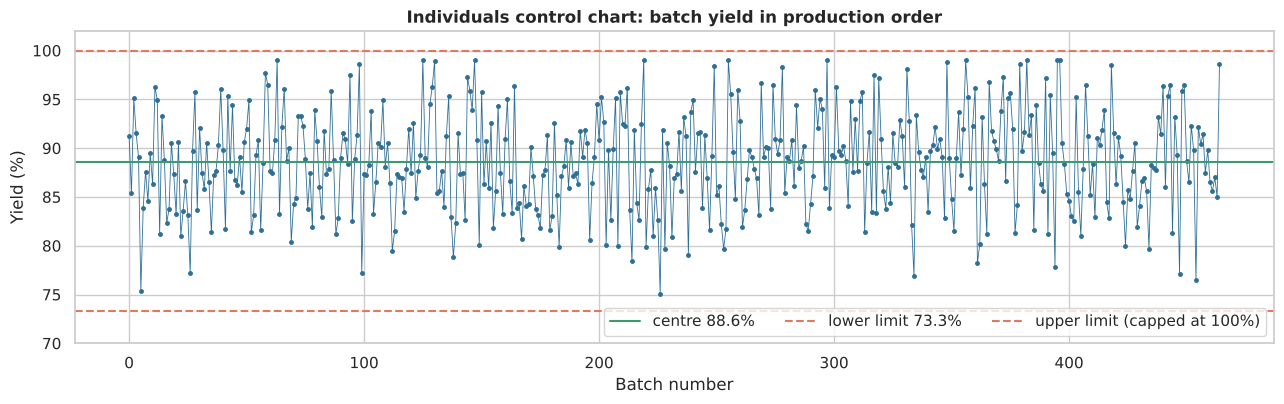

Batches outside the limits: 0 of 465 | correlation between one batch and the next: 0.01


In [3]:
c = extra["control"]
fig, ax = plt.subplots(figsize=(13, 4.2))
ax.plot(c["series"].index, c["series"].values, marker="o", ms=2.5, lw=0.6, color=BLUE)
ax.axhline(c["centre"], color=GREEN, label=f"centre {c['centre']:.1f}%")
ax.axhline(c["lcl"], color=ORANGE, ls="--", label=f"lower limit {c['lcl']:.1f}%")
ax.axhline(min(c["ucl"], 100), color=ORANGE, ls="--", label="upper limit (capped at 100%)")
ax.set(title="Individuals control chart: batch yield in production order", xlabel="Batch number", ylabel="Yield (%)", ylim=(70, 102)); ax.legend(loc="lower right", ncol=3)
save(fig, "fig22_yield_control_chart")
print(f"Batches outside the limits: {c['outside']} of {len(c['series'])} | correlation between one batch and the next: {c['lag1_autocorr']:.2f}")

**Finding.** **0 of 465 batches** fall outside the limits and consecutive batches are uncorrelated (0.01): yield varies randomly around 88.6%, so the process is **statistically stable** and there is nothing to investigate. (Yield cannot exceed 100%, so the upper limit is capped.)

## 3. Hypothesis tests: what is real?
We ran every question as a test. The **Holm** column corrects the p-values for running many tests. Read the verdict together with the effect size.

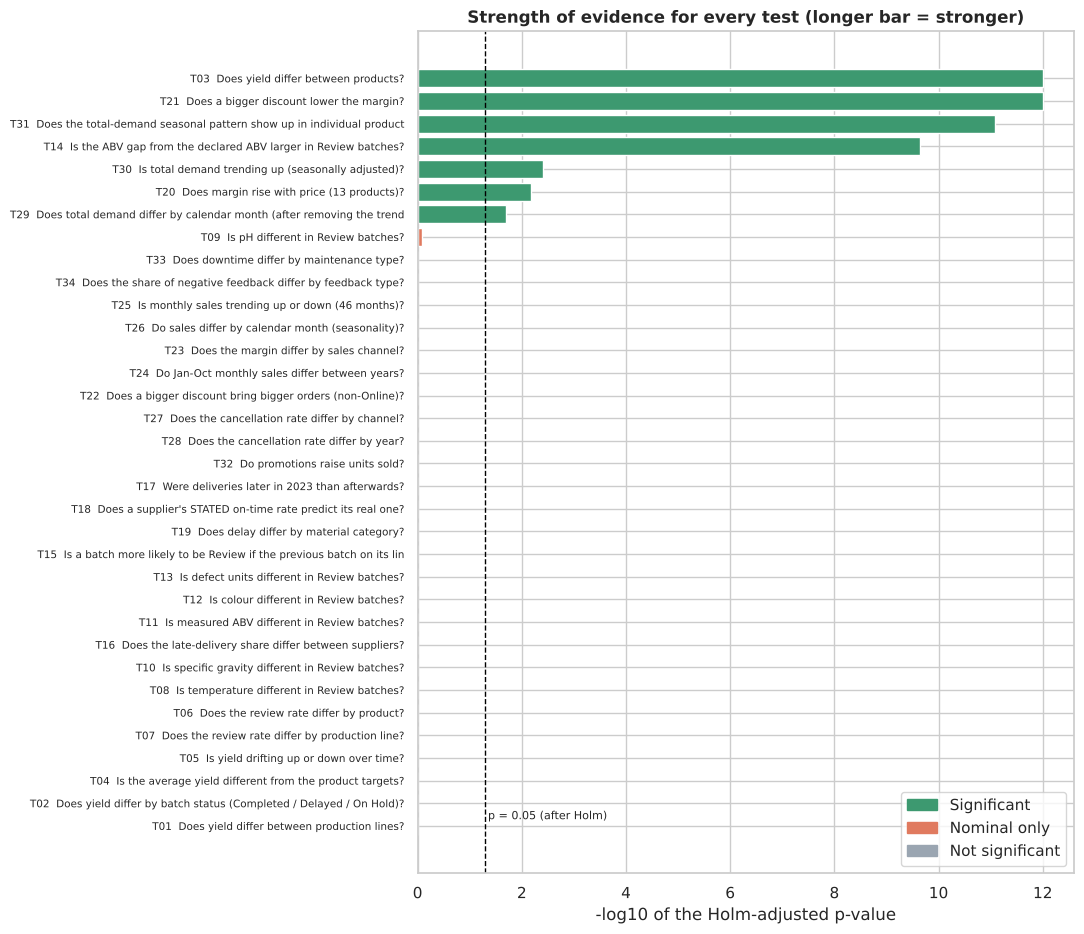

verdict
Not significant    26
Significant         7
Nominal only        1


,id,question,p_value,p_holm,effect_name,effect,verdict
2,T03,Does yield differ between products?,0.0000,0.0000,eta-squared,0.3211,Significant
8,T09,Is pH different in Review batches?,0.0311,0.8387,Cohen's d (Review - Pass),0.2689,Nominal only
13,T14,Is the ABV gap from the declared ABV larger in Review batches?,0.0000,0.0000,Cohen's d (Review - Pass),0.7961,Significant
19,T20,Does margin rise with price (13 products)?,0.0002,0.0067,r,0.8501,Significant
20,T21,Does a bigger discount lower the margin?,0.0000,0.0000,r,-0.4758,Significant
28,T29,Does total demand differ by calendar month (after removing the trend)?,0.0007,0.0199,eta-squared,0.7124,Significant
29,T30,Is total demand trending up (seasonally adjusted)?,0.0001,0.0038,units per month,256.7847,Significant
30,T31,Does the total-demand seasonal pattern show up in individual product-months?,0.0000,0.0000,rho,0.2931,Significant


In [4]:
t = tests.copy()
t["score"] = -np.log10(t["p_holm"].clip(lower=1e-12))
t = t.sort_values("score")
colors = t["verdict"].map({"Significant": GREEN, "Nominal only": ORANGE, "Not significant": GREY})
fig, ax = plt.subplots(figsize=(11, 9.5))
ax.barh(t["id"] + "  " + t["question"].str.slice(0, 68), t["score"], color=colors)
ax.axvline(-np.log10(0.05), color="black", ls="--", lw=1); ax.text(-np.log10(0.05) + 0.05, 0.3, "p = 0.05 (after Holm)", fontsize=8)
ax.set(title="Strength of evidence for every test (longer bar = stronger)", xlabel="-log10 of the Holm-adjusted p-value"); ax.tick_params(axis="y", labelsize=7.5)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=GREEN, label="Significant"), Patch(color=ORANGE, label="Nominal only"), Patch(color=GREY, label="Not significant")], loc="lower right")
save(fig, "fig23_test_overview")
print(tests["verdict"].value_counts().to_string())
display(tests[tests["verdict"] != "Not significant"][["id", "question", "p_value", "p_holm", "effect_name", "effect", "verdict"]].round(4))

**Finding.** **7 of 34 tests** survive the correction: yield differs between products (expected, since targets differ); the **ABV gap from the declared ABV** is larger in Review batches (d = 0.80); margin rises with price; deeper discounts lower the margin; total demand is seasonal and trending up; and the seasonal pattern shows in individual product-months. **One** test is only nominal (pH, p = 0.031, not significant after correction), and the other **26 show no evidence** of a difference: production lines, batch status, suppliers, channels, cancellations by year or channel, promotions, and maintenance types. Where the sample is small (about 35 batches per product), "no significant difference" means *inconclusive*, not "equal".

## 4. Discovery: Review is a specification check
Raw lab averages look the same for Pass and Review (errors go both ways and cancel). The right quantity is the **ABV gap** between the measured ABV and the product's *declared* ABV. The chart plots every batch against both quantities.

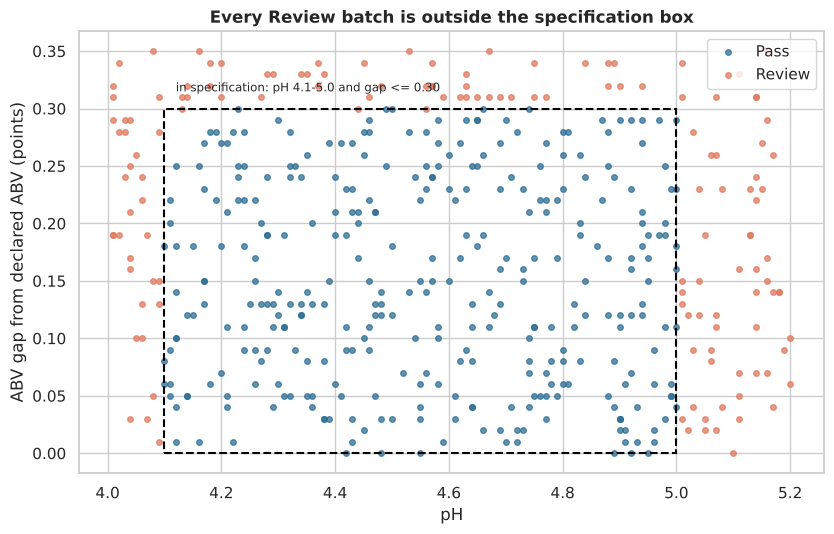

Rule matches 99.4% of batches: 135 flagged, 138 in Review, 0 false alarms, 3 missed
Inside the box: 330 batches, of which in Review: 3 (all sit exactly on the 0.30 boundary)


In [5]:
q = build_all(clean)["qc_features"].copy()
q["abv_gap"] = q["abs_abv_deviation"].round(2)
fig, ax = plt.subplots(figsize=(8.5, 5.5))
for rev, col, lab in [(False, BLUE, "Pass"), (True, ORANGE, "Review")]:
    d = q[q["is_review"] == rev]; ax.scatter(d["ph_value"], d["abv_gap"], s=16, alpha=0.75, color=col, label=lab)
ax.add_patch(Rectangle((4.1, 0), 0.9, 0.30, fill=False, ec="black", lw=1.5, ls="--"))
ax.text(4.12, 0.315, "in specification: pH 4.1-5.0 and gap <= 0.30", fontsize=8.5)
ax.set(title="Every Review batch is outside the specification box", xlabel="pH", ylabel="ABV gap from declared ABV (points)"); ax.legend(loc="upper right")
save(fig, "fig24_qc_specification")

out = (q["abv_gap"] > 0.30) | (q["ph_value"] < 4.1) | (q["ph_value"] > 5.0)
sr = extra["spec_rule"]
print(f"Rule matches {sr['accuracy']:.1%} of batches: {sr['flagged']} flagged, {sr['review']} in Review, {sr['false_alarms']} false alarms, {sr['missed']} missed")
print("Inside the box:", int((~out).sum()), "batches, of which in Review:", int((~out & q["is_review"]).sum()), "(all sit exactly on the 0.30 boundary)")

**Finding.** Inside the dashed box (pH 4.1 to 5.0 and ABV gap up to 0.30) there are 330 batches and only 3 are in Review; outside it, **every** batch is in Review. The rule matches **99.4%** of batches, and the 3 misses lie exactly on the 0.30 boundary where rounding decides. This is the clearest example of **feature engineering paying off**: the raw columns hid the rule. Two warnings: the thresholds were found by looking at the data, so confirm them with the brewery; and a model that classifies Review from these measurements will only *rediscover this rule*.

## 5. Profitability: price, discount and margin

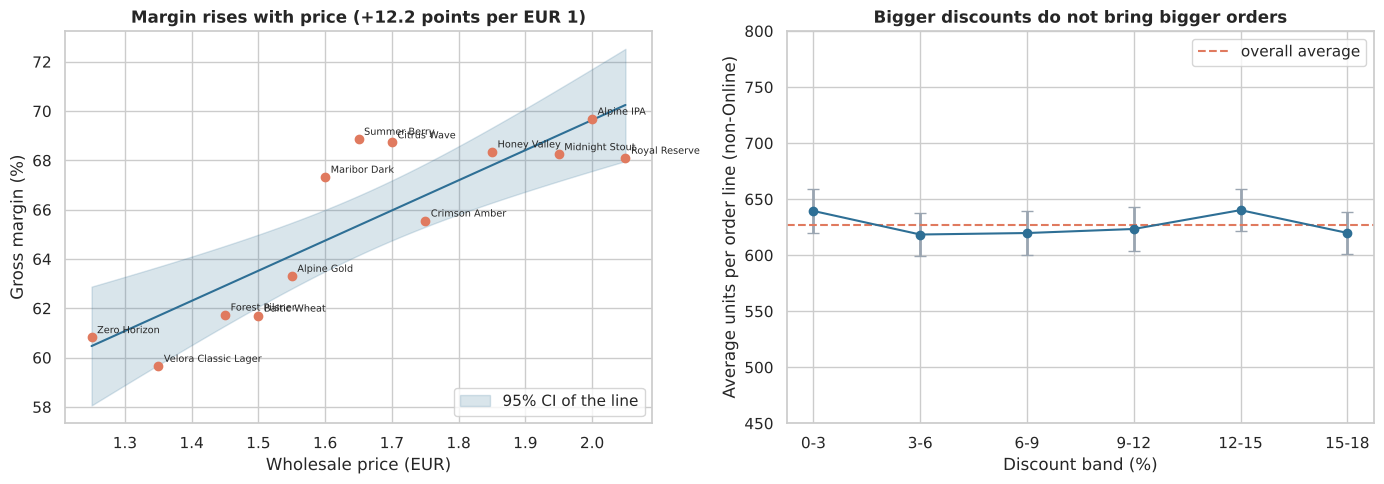

,quantity,estimate,low,high,unit
27,"Gross margin, Zero Horizon",60.82,60.57,61.06,%
28,Margin gain per +1 EUR wholesale price,12.22,7.20,17.25,points
29,Margin change per +1 point of discount,-0.39,-0.40,-0.37,points
30,Units per line change per +1 point of discount (non-Online),-0.27,-1.77,1.23,units


In [6]:
pr = extra["price_fit"].copy()
x, yv = pr["price"].values, pr["margin"].values * 100
n = len(x); slope, intercept = np.polyfit(x, yv, 1)
resid = yv - (intercept + slope * x); s = np.sqrt((resid ** 2).sum() / (n - 2)); sxx = ((x - x.mean()) ** 2).sum()
xs = np.linspace(x.min(), x.max(), 60); se = s * np.sqrt(1 / n + (xs - x.mean()) ** 2 / sxx); tcrit = stats.t.ppf(0.975, n - 2)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].fill_between(xs, intercept + slope * xs - tcrit * se, intercept + slope * xs + tcrit * se, color=BLUE, alpha=0.18, label="95% CI of the line")
ax[0].plot(xs, intercept + slope * xs, color=BLUE); ax[0].scatter(x, yv, color=ORANGE, zorder=3)
for name, row in pr.iterrows(): ax[0].annotate(name, (row["price"], row["margin"] * 100), fontsize=7, xytext=(4, 3), textcoords="offset points")
ax[0].set(title=f"Margin rises with price (+{slope:.1f} points per EUR 1)", xlabel="Wholesale price (EUR)", ylabel="Gross margin (%)"); ax[0].legend(loc="lower right")

sl = clean["sales_lines"]; nz = sl[(~sl["is_cancelled"]) & (sl["sales_channel"] != "Online")].copy()
nz["band"] = pd.cut(nz["discount_rate"] * 100, [-0.1, 3, 6, 9, 12, 15, 18.1], labels=["0-3", "3-6", "6-9", "9-12", "12-15", "15-18"])
g = nz.groupby("band", observed=True)["quantity_units"].agg(["mean", "sem", "count"])
ax[1].errorbar(range(len(g)), g["mean"], yerr=1.96 * g["sem"], fmt="o-", color=BLUE, ecolor=GREY, capsize=4, elinewidth=2)
ax[1].axhline(nz["quantity_units"].mean(), color=ORANGE, ls="--", label="overall average")
ax[1].set(title="Bigger discounts do not bring bigger orders", xlabel="Discount band (%)", ylabel="Average units per order line (non-Online)", ylim=(450, 800))
ax[1].set_xticks(range(len(g))); ax[1].set_xticklabels(g.index.astype(str)); ax[1].legend()
save(fig, "fig25_profitability")
display(cis[cis["area"] == "Profit"][["quantity", "estimate", "low", "high", "unit"]].tail(4).round(2))

**Finding.** Each extra EUR 1 of wholesale price adds **12.2 points of margin** (95% CI 7.2 to 17.2; r = 0.85 across 13 products). Each extra point of discount lowers margin by **0.39 points** (CI -0.40 to -0.37), which is partly arithmetic: revenue falls while cost stays. Discounts do **not** raise order size: units per line change by -0.3 per point (CI -1.8 to +1.2), so a 10-point discount could lift a typical order (about 627 units) by at most about 2%, far below the roughly 11% a 10% price cut needs to keep revenue level.

## 6. Seasonality and trend in demand
Seasonality is a repeating yearly pattern; the **trend** is the long-run direction. We remove the straight-line trend first, then ask whether the calendar month explains what is left.

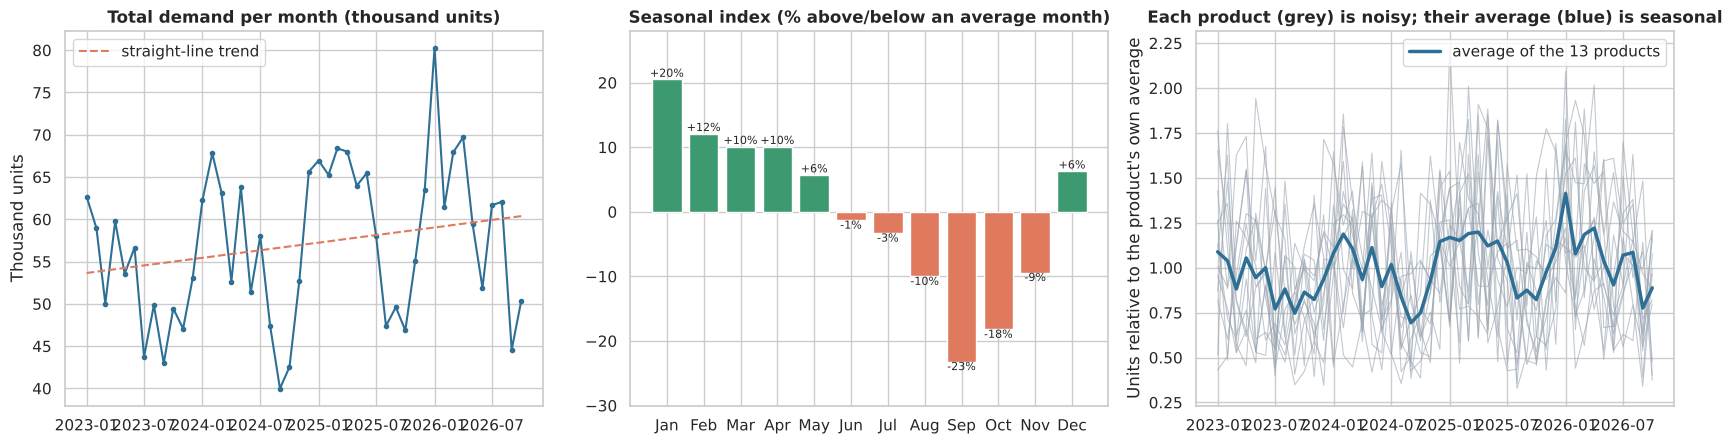

Calendar month explains 71% of the detrended variation in total demand
Products with a significant month effect on their own: 1 of 13


,quantity,estimate,low,high,unit
36,Demand trend per month (seasonally adjusted),257.0,136.0,377.0,units / month


In [7]:
tot, idx = extra["total_demand"], extra["seasonal_index"]
dem = clean["demand"][~clean["demand"]["is_forecast_period"]]
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
ax[0].plot(tot.index, tot.values / 1000, marker="o", ms=3, color=BLUE)
lr = stats.linregress(np.arange(len(tot)), tot.values); ax[0].plot(tot.index, (lr.intercept + lr.slope * np.arange(len(tot))) / 1000, color=ORANGE, ls="--", label="straight-line trend")
ax[0].set(title="Total demand per month (thousand units)", ylabel="Thousand units"); ax[0].legend()
bars = ax[1].bar([calendar.month_abbr[m] for m in idx.index], idx.values, color=[GREEN if v > 0 else ORANGE for v in idx.values])
ax[1].bar_label(bars, fmt="%+.0f%%", fontsize=8); ax[1].set(title="Seasonal index (% above/below an average month)", ylim=(-30, 28))
pv = dem.pivot_table(index="month", columns="product_id", values="units_sold"); rel = pv / pv.mean()
for c in rel.columns: ax[2].plot(rel.index, rel[c], color=GREY, lw=0.8, alpha=0.6)
ax[2].plot(rel.index, rel.mean(axis=1), color=BLUE, lw=2.5, label="average of the 13 products")
ax[2].set(title="Each product (grey) is noisy; their average (blue) is seasonal", ylabel="Units relative to the product's own average"); ax[2].legend()
save(fig, "fig26_seasonality")
print(f"Calendar month explains {extra['seasonal_eta2']:.0%} of the detrended variation in total demand")
print(f"Products with a significant month effect on their own: {extra['products_with_seasonality']} of {extra['n_products']}")
display(cis[cis["quantity"].str.contains("Demand trend")][["quantity", "estimate", "low", "high", "unit"]].round(0))

**Finding.** Total demand is **clearly seasonal**: after removing the trend, calendar month explains **71%** of the variation, with January about **+20%** above an average month and September about **-23%** below. Demand also **trends up** by **257 units per month** (95% CI 136 to 377), a trend a simple test misses (p = 0.13) because the seasonal swings hide it. But each product on its own is very noisy (only **1 of 13** shows seasonality by itself, right chart): the pattern appears when products are added up, and it still correlates (rho = 0.29) with product-months pooled together. So the seasonal signal is real but small per product.

## 7. Feature engineering
Features are columns a model can learn from. We build five tables (`src/features.py`):
`demand_features`, `qc_features`, `product_month_features`, `customer_features`, `supplier_features`.
**Leakage rule:** a feature for time t may only use information known *before* t.

In [8]:
F = build_all(clean)
overview = pd.DataFrame([[k, len(v), v.shape[1]] for k, v in F.items()], columns=["table", "rows", "columns"]); display(overview)
d = F["demand_features"]
print("\nDemand features: one product (VLR001), months 12-17 - read each row left to right")
display(d[d["product_id"] == "VLR001"][["month", "units_sold", "units_lag1", "units_lag12", "units_roll_mean_3", "seasonal_index", "total_units_lag1"]].iloc[12:18])
print("Customer features (RFM): first 4 customers")
display(F["customer_features"][["customer_id", "recency_days", "frequency", "monetary", "avg_order_value", "tenure_days", "cancel_rate"]].head(4).round(1))

,table,rows,columns
0,demand_features,598,31
1,qc_features,465,28
2,product_month_features,598,20
3,customer_features,600,16
4,supplier_features,20,14



Demand features: one product (VLR001), months 12-17 - read each row left to right


,month,units_sold,units_lag1,units_lag12,units_roll_mean_3,seasonal_index,total_units_lag1
12,2024-01-01,5874,1634.0,5351.0,2913.333333,15.7,53006.0
13,2024-02-01,6122,5874.0,3396.0,3595.333333,15.5,62269.0
14,2024-03-01,5837,6122.0,2849.0,4543.333333,9.1,67798.0
15,2024-04-01,3047,5837.0,5213.0,5944.333333,8.1,63154.0
16,2024-05-01,6866,3047.0,6017.0,5002.000000,8.4,52633.0
17,2024-06-01,3050,6866.0,3952.0,5250.000000,3.5,63764.0


Customer features (RFM): first 4 customers


,customer_id,recency_days,frequency,monetary,avg_order_value,tenure_days,cancel_rate
0,CUS0001,231.0,5.0,11858.9,2371.8,1011.0,0.2
1,CUS0002,926.0,5.0,9575.7,1915.1,1203.0,0.2
2,CUS0003,5.0,4.0,3358.3,839.6,1221.0,0.2
3,CUS0004,57.0,7.0,12884.8,1840.7,1375.0,0.1


**Reading the table.** In the row for 2024-03, `units_lag1` is the February units, `units_lag12` is March 2023, and `units_roll_mean_3` is the average of December, January and February (the current month is **not** in it). That one-period shift is what keeps the features honest.

### Proof that the features do not peek at the future
`test_features.py` changes the future on purpose (test-year units set to 10 million, later QC outcomes flipped) and checks that earlier features do not move.

In [9]:
import test_features
try:
    test_features.main()
except SystemExit:
    pass

1. Correctness
  [OK  ] units_lag1 equals last month's units for every product
  [OK  ] units_lag12 equals the same month last year
  [OK  ] units_roll_mean_3 is the mean of the 3 PREVIOUS months (current month excluded)
  [OK  ] first month of every product has no lag (nothing is back-filled)
  [OK  ] the forecast-period months (after 2026-10-31) are not in the demand features
  [OK  ] month_sin / month_cos stay between -1 and 1
  [OK  ] customer monetary values add up to total net sales (cancelled excluded)
  [OK  ] customer frequency adds up to the non-cancelled orders
  [OK  ] recency_days is never negative
  [OK  ] no infinite values in any feature table

2. Leakage (change the future, earlier features must not move)
  [OK  ] seasonal_index does not change when the TEST years are altered (learned from training years only)
  [OK  ] lag and rolling features for training rows are unchanged when future units are altered
  [OK  ] Jan 2026 lag1 (Dec 2025 units, still known) is unchanged

### Do the features carry any signal?
We check each feature's correlation with the target, and compare simple forecasts with each other. Any model in the next step must beat the best simple forecast.

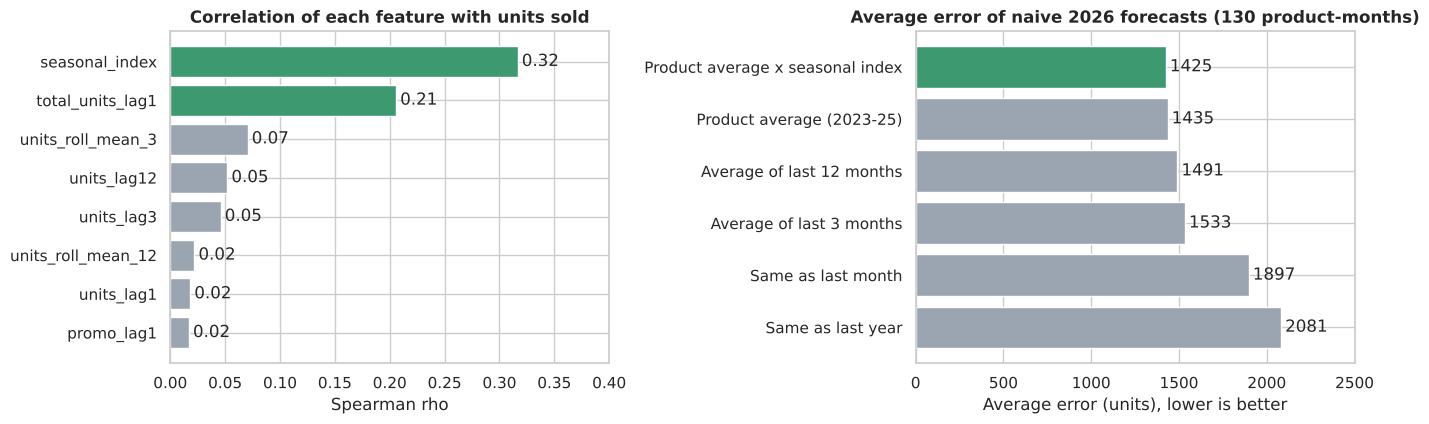

Before-the-test QC features significant at 5%: 0 of 11 (smallest p = 0.057)


In [10]:
dd = d[d["has_full_history"]]
cols = ["units_lag1", "units_lag3", "units_lag12", "units_roll_mean_3", "units_roll_mean_12", "promo_lag1", "total_units_lag1", "seasonal_index"]
rho = pd.Series({c: stats.spearmanr(dd[c], dd["units_sold"])[0] for c in cols}).sort_values()
train, test = dd[dd["month"] <= TRAIN_END], dd[dd["month"] > TRAIN_END]
pm_ = test["product_id"].map(train.groupby("product_id")["units_sold"].mean())
mae = lambda p: float(np.abs(test["units_sold"] - p).mean())
base = pd.Series({"Product average x seasonal index": mae(pm_ * (1 + test["seasonal_index"] / 100)), "Product average (2023-25)": mae(pm_),
                  "Average of last 12 months": mae(test["units_roll_mean_12"]), "Average of last 3 months": mae(test["units_roll_mean_3"]),
                  "Same as last month": mae(test["units_lag1"]), "Same as last year": mae(test["units_lag12"])}).sort_values(ascending=False)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.4))
b = ax[0].barh(rho.index, rho.values, color=[GREEN if v > 0.15 else GREY for v in rho.values]); ax[0].bar_label(b, fmt="%.2f", padding=3)
ax[0].set(title="Correlation of each feature with units sold", xlabel="Spearman rho", xlim=(0, 0.4))
b = ax[1].barh(base.index, base.values, color=[GREEN if i == len(base) - 1 else GREY for i in range(len(base))]); ax[1].bar_label(b, fmt="%.0f", padding=3)
ax[1].set(title=f"Average error of naive 2026 forecasts ({len(test)} product-months)", xlabel="Average error (units), lower is better", xlim=(0, 2500))
save(fig, "fig27_feature_signal")

qa = F["qc_features"]
before = ["planned_volume_litre", "yield_rate", "loss_pct", "cost_per_litre", "shift_count", "month_no", "days_since_prev_batch_line",
          "prev_batch_review_line", "review_rate_prev10_line", "prev_yield_line", "yield_roll5_prev_line"]
pvals = {}
for c in before:
    m = qa[c].notna(); pvals[c] = stats.pointbiserialr(qa.loc[m, "is_review"].astype(float), qa.loc[m, c])[1]
print(f"Before-the-test QC features significant at 5%: {sum(v < 0.05 for v in pvals.values())} of {len(pvals)} (smallest p = {min(pvals.values()):.3f})")

**Finding.** Last-month, last-year and recent-average features have almost no relationship with units sold (rho 0.02 to 0.07), and **a forecast of "same as last month" is worse than simply using the product's average** (average error 1,897 versus 1,435 units). Only the seasonal index (0.32) and total-market level (0.21) help, and the best simple forecast, the product average times the seasonal index, is only slightly better than the plain average (1,425 vs 1,435). For QC, **none of the 11 features known before the lab test** is significant (0 of 11), so an early-warning model has almost nothing to learn from; features known after the test define the rule found in Section 4.

## 8. Summary

| # | Area | Result |
|---|---|---|
| 1 | Precision | Yield 88.6%, review rate 29.7%, late deliveries 57.2%, margin 66.0%, each with a 95% CI |
| 2 | Quality | The yield process is stable (0 of 465 batches outside control limits) |
| 3 | Quality | Review is a specification check: pH outside 4.1-5.0 or ABV gap above 0.30 (99.4% match) |
| 4 | Profit | +12.2 margin points per EUR 1 of price; -0.39 points per point of discount; discounts add no volume |
| 5 | Demand | Seasonal (calendar month explains 71% of total variation) and rising (+257 units per month) |
| 6 | Features | Lag features carry almost no signal; the seasonal index and ABV gap are the useful engineered features |
| 7 | Tests | 7 of 34 tests survive correction; 26 found no evidence of a difference |

**Handover to Step 8 (machine learning):** (1) QC needs two problems: classify from after-test measurements (rediscovers the rule, near-perfect) and early warning from before-test features (expect weak results). (2) Demand models must beat "product average x seasonal index". (3) Use `customer_features` for clustering.